Logistic Regression accuracy: 0.9333
-----Logistic Regression Confusion Matrix-----
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



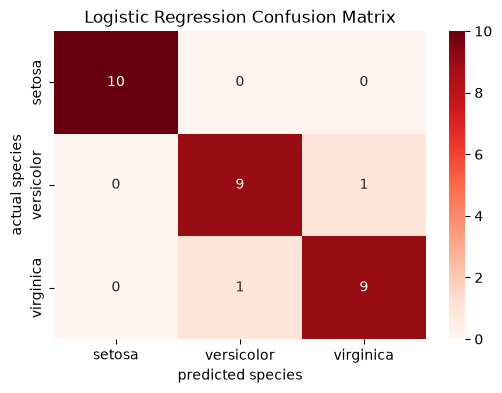

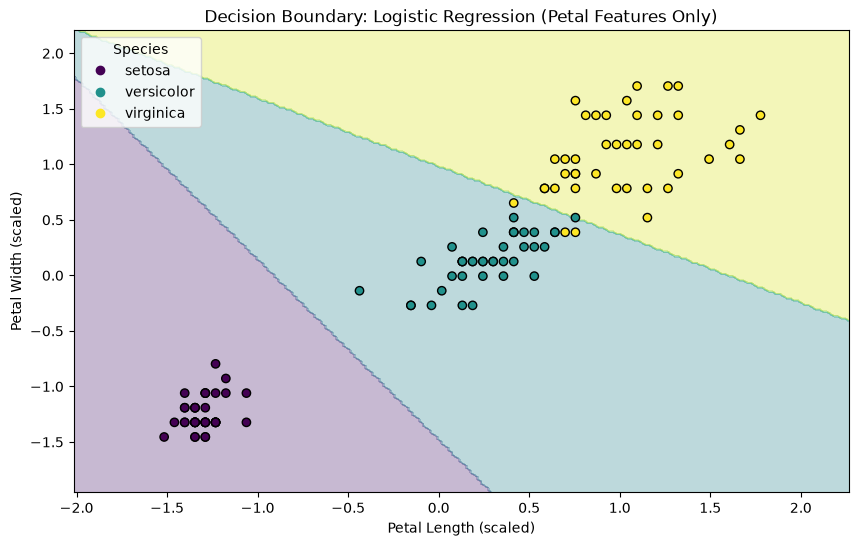

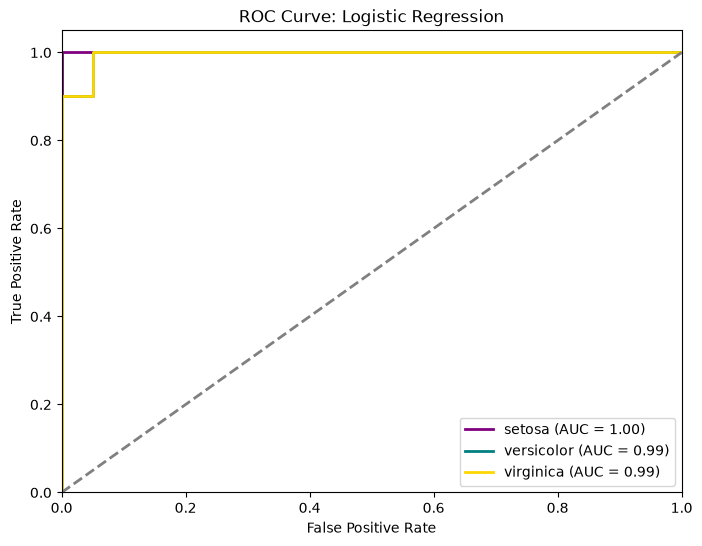

Decision Tree accuracy: 0.9333
-----Decision Tree Classification Report-----
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



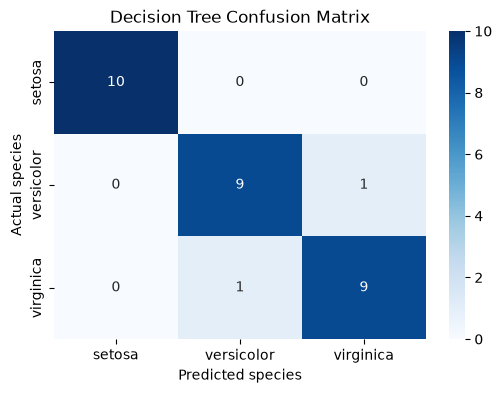

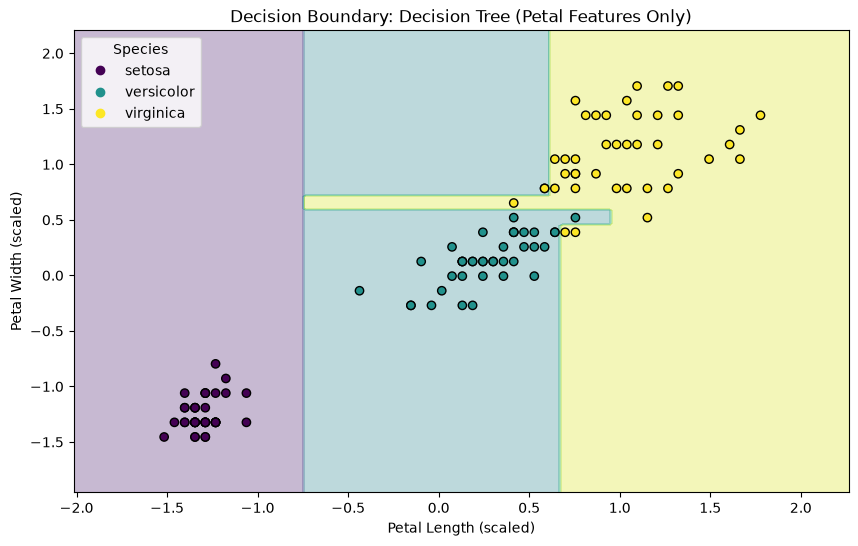

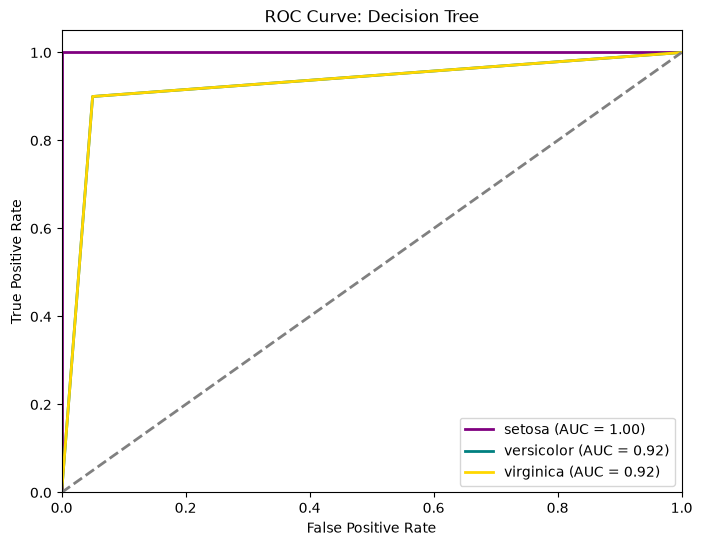

In [117]:
'''# Multi-Class Benchmark Classification Pipeline (Iris)
**Objective:** Build an end-to-end machine learning pipeline to classify Iris species using Logistic Regression and Decision Trees. 
This notebook covers data loading, exploratory data analysis (EDA), feature scaling, model training, performance evaluation (confusion matrices & ROC curves), 
and decision boundary visualization.

**Dataset:** Iris Dataset (150 samples, 4 features, 3 classes).
'''
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

'''-----------------------------------1. Data Loading & Preprocessing-----------------------------------'''
#loading CSV file
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
df = pd.read_csv(url)

col = df.columns.tolist()
#Data Cleaning
hasNan = df.isna().any().any()
df = df.dropna()

#finiding mean, median, mode and std
col_name = {'sepal_length':{}, 'sepal_width':{}, 'petal_length':{}, 'petal_width':{}}
for name in col_name:
    col_name[name]['mean'] = float(round(df[name].mean(), 2))
    col_name[name]['median'] = float(round(df[name].median(), 2))
    col_name[name]['mode'] = df[name].mode().tolist()
    col_name[name]['std'] = float(round(df[name].std(), 2))

#counting the number of occurances and giving the lables to each specie
species_name = {}
lable_num = 0

for n in df['species']:
    if n not in species_name:
        species_name[n] = {'count' : 1, 'lable' : lable_num}
        lable_num += 1
    else:
        species_name[n]['count'] += 1

#print(species_name)
'''-----------------------------------2. Feature Extraction & Train/Test Split-----------------------------------'''
input_x = df[col[:4]].to_numpy()
target_y = np.array([species_name[s]['lable'] for s in df['species']])

train_x, test_x, train_y, test_y = train_test_split(input_x, target_y, test_size=0.2, random_state=42, stratify=target_y)

count = {'zero': 0, 'one': 0, 'two': 0}
for i in train_y:
    if i == 0:
        count['zero'] += 1
    elif i == 1:
        count['one'] += 1
    else:
        count['two'] += 1
#print(count)

count = {'zero': 0, 'one': 0, 'two': 0}
for i in test_y:
    if i == 0:
        count['zero'] += 1
    elif i == 1:
        count['one'] += 1
    else:
        count['two'] += 1
#print(count)

'''-----------------------------------3. Training the Scaler-----------------------------------'''
'''
3. Feature Scaling
We use `StandardScaler` to normalize the features. 
Because Logistic Regression uses gradient descent, it is highly sensitive to feature scale. Decision Trees are scale-invariant, 
but we scale the data for both to maintain a consistent pipeline. 

*Crucial: The scaler is fit ONLY on the training data and transformed on the test data to prevent data leakage.*
'''
scaler = StandardScaler()
train_x_cal = {'sepal_length':{}, 'sepal_width':{}, 'petal_length':{}, 'petal_width':{}}
for i, col_name in enumerate(train_x_cal):
    train_x_cal[col_name]['mean'] = float(round(train_x[: , i].mean(), 2))
    train_x_cal[col_name]['std'] = float(round(train_x[:,i].std(), 2))
#print(train_x_cal)

train_x_scaled = scaler.fit_transform(train_x)
test_x_scaled = scaler.transform(test_x)

'''-----------------------------------4. Logistic Regression-----------------------------------
   -----------------------------------Step 1: Training the Model-----------------------------------'''
lr_model = LogisticRegression(max_iter = 1000)
lr_model.fit(train_x_scaled, train_y)
lr_preds = lr_model.predict(test_x_scaled)

'''-----------------------------------Step 2: Accuracy Score-----------------------------------'''

lr_acc = accuracy_score(test_y, lr_preds)
print(f'Logistic Regression accuracy: {lr_acc:.4f}')

'''-----------------------------------Step 3: Confusion Matrix-----------------------------------'''

print('-----Logistic Regression Confusion Matrix-----')
target_names = [name for name in species_name]
print(classification_report(test_y, lr_preds, target_names=target_names))
lr_cm = confusion_matrix(test_y, lr_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Reds', xticklabels=target_names, yticklabels=target_names)
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('predicted species')
plt.ylabel('actual species')
plt.show()

'''-----------------------------------Step 4: Boundary Visualisation-----------------------------------'''
x_2d = input_x[:, [2,3]]
y_2d = target_y

x_train_2d, x_test_2d, y_train_2d, y_test_2d = train_test_split(x_2d, y_2d, test_size=0.2, random_state=42, stratify=y_2d)

scaler_2d = StandardScaler()
train_2d_x_scaled = scaler_2d.fit_transform(x_train_2d)
test_2d_x_scaled = scaler_2d.transform(x_test_2d)

lr_model_2d = LogisticRegression(max_iter= 1000)
lr_model_2d.fit(train_2d_x_scaled, y_train_2d)

x_min, x_max = train_2d_x_scaled[:, 0].min() - 0.5, train_2d_x_scaled[:, 0].max() + 0.5
y_min, y_max = train_2d_x_scaled[:, 1].min() - 0.5, train_2d_x_scaled[:, 1].max() + 0.5

# Create a grid of dots spaced 0.02 apart
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# 6. Predict the species for EVERY dot on the grid
Z = lr_model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape) # Reshape back to 2D grid

# 7. Draw the plot
plt.figure(figsize=(10, 6))

# Draw the colored background regions (the decision boundaries)
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

# Plot the actual training flowers as dots on top
scatter = plt.scatter(
    train_2d_x_scaled[:, 0], 
    train_2d_x_scaled[:, 1], 
    c=y_train_2d, 
    edgecolor='k', 
    cmap='viridis'
)

# Add labels and title
plt.xlabel('Petal Length (scaled)')
plt.ylabel('Petal Width (scaled)')
plt.title('Decision Boundary: Logistic Regression (Petal Features Only)')

# Add a legend
handles, _ = scatter.legend_elements()
plt.legend(handles, ['setosa', 'versicolor', 'virginica'], title="Species")
plt.show()


'''-----------------------------------Step 5: ROC Curve-----------------------------------'''
# 1. Binarize the output
y_test_bin = label_binarize(test_y, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]
target_names = ['setosa', 'versicolor', 'virginica']
colors = ['purple', 'teal', 'gold']

# 2. Get probabilities for Logistic Regression
lr_probs = lr_model.predict_proba(test_x_scaled)

# 3. Plot
plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], lr_probs[:, i])
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, color=colors[i], lw=2,
             label=f'{target_names[i]} (AUC = {roc_auc:.2f})')

# Plot random guess line
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Logistic Regression')
plt.legend(loc="lower right")
plt.show()

'''-----------------------------------5. Decision Tree-----------------------------------
   -----------------------------------Step 1: Training the Model-----------------------------------'''

dt_model = DecisionTreeClassifier(random_state = 42)
dt_model.fit(train_x_scaled, train_y)
dt_preds = dt_model.predict(test_x_scaled)

'''-----------------------------------Step 2: Accuracy Score-----------------------------------'''
dt_acc = accuracy_score(test_y, dt_preds)
print(f'Decision Tree accuracy: {dt_acc:.4f}')

'''-----------------------------------Step 3: Confusion Matrix-----------------------------------'''
print('-----Decision Tree Classification Report-----')
print(classification_report(test_y, dt_preds, target_names=target_names))
cm = confusion_matrix(test_y, dt_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted species')
plt.ylabel('Actual species')
plt.show()

'''-----------------------------------Step 4: Boundary Visualisation-----------------------------------'''
dt_model_2d = DecisionTreeClassifier(random_state=42)
dt_model_2d.fit(train_2d_x_scaled, y_train_2d)

dt_x_min, dt_x_max = train_2d_x_scaled[:, 0].min() - 0.5, train_2d_x_scaled[:, 0].max() + 0.5
dt_y_min, dt_y_max = train_2d_x_scaled[:, 1].min() - 0.5, train_2d_x_scaled[:, 1].max() + 0.5

# Create a grid of dots spaced 0.02 apart
dt_xx, dt_yy = np.meshgrid(
    np.arange(dt_x_min, dt_x_max, 0.02),
    np.arange(dt_y_min, dt_y_max, 0.02)
)

# 6. Predict the species for EVERY dot on the grid
dt_Z = dt_model_2d.predict(np.c_[dt_xx.ravel(), dt_yy.ravel()])
dt_Z = dt_Z.reshape(dt_xx.shape) # Reshape back to 2D grid

# 7. Draw the plot
plt.figure(figsize=(10, 6))

# Draw the colored background regions (the decision boundaries)
plt.contourf(dt_xx, dt_yy, dt_Z, alpha=0.3, cmap='viridis')

# Plot the actual training flowers as dots on top
dt_scatter = plt.scatter(
    train_2d_x_scaled[:, 0], 
    train_2d_x_scaled[:, 1], 
    c=y_train_2d, 
    edgecolor='k', 
    cmap='viridis'
)

# Add labels and title
plt.xlabel('Petal Length (scaled)')
plt.ylabel('Petal Width (scaled)')
plt.title('Decision Boundary: Decision Tree (Petal Features Only)')

# Add a legend
dt_handles, _ = dt_scatter.legend_elements()
plt.legend(dt_handles, ['setosa', 'versicolor', 'virginica'], title="Species")
plt.show()

'''-----------------------------------Step 5: ROC Curve-----------------------------------'''
# 1. Get probabilities for Decision Tree
dt_probs = dt_model.predict_proba(test_x_scaled)

# 2. Plot
plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], dt_probs[:, i])
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, color=colors[i], lw=2,
             label=f'{target_names[i]} (AUC = {roc_auc:.2f})')

# Plot random guess line
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Decision Tree')
plt.legend(loc="lower right")
plt.show()

'''
Final Performance Summary

1. Model Accuracy & Classification Report
Both Logistic Regression and Decision Tree models achieved an overall **accuracy of 93.33%** (28 out of 30 test samples correct). 
*   Setosa: Both models achieved a perfect 1.00 Precision, Recall, and F1-score. This proves Setosa is linearly separable and distinctly different from the other two species.
*   Versicolor & Virginica: Both models achieved 0.90 Precision, Recall, and F1-score. The models made exactly one error each way (1 versicolor misclassified as virginica, 
    and 1 virginica misclassified as versicolor).

2. Interpreting the Confusion Matrices
The confusion matrices visually confirm the classification reports. 
*   The diagonal from top-left to bottom-right represents correct predictions. You can see 10 Setosa, 9 Versicolor, and 9 Virginica were correctly identified.
*   The off-diagonal values (the 1s) represent misclassifications. Because versicolor and virginica overlap in their petal measurements (as seen in the EDA pairplot), 
    the models struggled slightly to draw a perfect boundary between them.

3. Interpreting the Decision Boundaries
Because the data is 4-dimensional, we isolated the two most important features (`petal_length` and `petal_width`) to visualize the models in 2D space:
*   Logistic Regression: The plot shows straight, diagonal lines separating the classes. Because it is a linear model, it cannot "bend" around the overlapping versicolor/virginica dots,
    which explains the misclassifications.
*   Decision Tree: The plot shows a "staircase" or blocky pattern with perpendicular lines. Because Decision Trees use a series of "Yes/No" thresholds (e.g., "Is Petal Length > X?"), 
    they draw rectangular decision regions rather than smooth diagonal lines.

4. Interpreting the ROC Curves
The Receiver Operating Characteristic (ROC) curves evaluate the models based on predicted probabilities rather than just hard class labels.
*   The Area Under the Curve (AUC) score for **Setosa** is a perfect **1.00** for both models (the line shoots straight into the top-left corner).
*   The AUC scores for Versicolor and Virginica are **~0.98**, indicating the models are highly confident in their predictions and successfully separate the 
    overlapping classes the vast majority of the time. 
    
*   *Conclusion:* Both models are highly robust, and the small number of errors is due to the natural biological overlap of the flower measurements, 
    not a flaw in the model architecture.
'''